# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 제출 정보

- 이름: 권혁수
- GitHub ID: kwonhyeoksoo
- 작성일: 2026-10-30
- 최종 제출 URL: https://github.com/kwonhyeoksoo/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: c:\dev\llm-data-analysis-study\llm-data-analysis-course\notebooks
프로젝트 루트: c:\dev\llm-data-analysis-study\llm-data-analysis-course
전처리 데이터 폴더: c:\dev\llm-data-analysis-study\llm-data-analysis-course\data\processed
그래프 저장 폴더: c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [2]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(PROCESSED_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic


ValueError: 주문 정보와 연결되지 않은 주문 상세가 있습니다: 2행

In [4]:
import pandas as pd
from pathlib import Path

order_items_chk = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')
orders_chk = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')

orphan_ids = set(order_items_chk['order_id']) - set(orders_chk['order_id'])
print('orders에 없는 order_id:', orphan_ids)
print(order_items_chk[order_items_chk['order_id'].isin(orphan_ids)])

orders에 없는 order_id: {9992, 9991}
     order_item_id  order_id  product_id  quantity  unit_price  line_total
147            150      9991          89       5.0    178000.0    890000.0
609            620      9992          98       1.0     32000.0     32000.0


In [5]:
VIZ_DIR = PROJECT_ROOT / 'data' / 'processed_viz'
VIZ_DIR.mkdir(exist_ok=True)

for name in ['customers', 'products', 'orders']:
    pd.read_csv(PROCESSED_DIR / f'{name}_clean.csv').to_csv(
        VIZ_DIR / f'{name}_clean.csv', index=False, encoding='utf-8-sig')

order_items_viz = order_items_chk[~order_items_chk['order_id'].isin(orphan_ids)]
order_items_viz.to_csv(VIZ_DIR / 'order_items_clean.csv', index=False, encoding='utf-8-sig')

print('제외한 행 수:', len(order_items_chk) - len(order_items_viz))

제외한 행 수: 2


In [6]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(VIZ_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic


ValueError: 상품 정보와 연결되지 않은 완료 주문 상세가 있습니다: 16행

In [7]:
items_v = pd.read_csv(VIZ_DIR / 'order_items_clean.csv')
orders_v = pd.read_csv(VIZ_DIR / 'orders_clean.csv')
products_v = pd.read_csv(VIZ_DIR / 'products_clean.csv')

comp = items_v.merge(orders_v[['order_id', 'order_status']], on='order_id', how='left')
comp = comp[comp['order_status'] == 'completed']

missing_prod = comp[~comp['product_id'].isin(products_v['product_id'])]
print('completed 원본 합계(고아 2건 제외 후):', comp['line_total'].sum())
print('상품 미연결 completed 행 수:', len(missing_prod))
print('상품 미연결 product_id:', sorted(missing_prod['product_id'].unique()))
print('상품 미연결 금액 합계:', missing_prod['line_total'].sum())

completed 원본 합계(고아 2건 제외 후): 141340000.0
상품 미연결 completed 행 수: 16
상품 미연결 product_id: [np.int64(18), np.int64(48), np.int64(73), np.int64(95), np.int64(9991)]
상품 미연결 금액 합계: 4015000.0


In [8]:
bad_product_ids = set(missing_prod['product_id'])
mask_bad = items_v['product_id'].isin(bad_product_ids) & ~items_v['product_id'].isin(products_v['product_id'])

completed_ids = set(orders_v.loc[orders_v['order_status'] == 'completed', 'order_id'])
drop_mask = mask_bad & items_v['order_id'].isin(completed_ids)

items_v2 = items_v[~drop_mask]
items_v2.to_csv(VIZ_DIR / 'order_items_clean.csv', index=False, encoding='utf-8-sig')
print('추가 제외 행 수:', drop_mask.sum())

추가 제외 행 수: 16


In [9]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(VIZ_DIR)

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 430
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 6


In [10]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,137325000.0,137325000.0,0.0,True
1,product_completed_amount,137325000.0,137325000.0,0.0,True
2,customer_completed_amount,137325000.0,137325000.0,0.0,True
3,monthly_completed_amount_valid_dates,135422000.0,135422000.0,0.0,True


In [11]:
for k, v in viz_data.items():
    print(k, type(v).__name__, getattr(v, "shape", ""))

customers DataFrame (150, 6)
products DataFrame (96, 4)
orders DataFrame (300, 7)
order_items DataFrame (734, 6)
order_sales DataFrame (734, 9)
completed_order_sales DataFrame (430, 9)
completed_sales_items DataFrame (430, 12)
category_sales DataFrame (10, 4)
monthly_sales DataFrame (15, 5)
product_sales DataFrame (95, 6)
customer_sales DataFrame (99, 4)
order_status DataFrame (3, 2)
invalid_date_sales DataFrame (6, 9)
visualization_validation DataFrame (4, 5)


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: visualization_validation의 4개 항목(카테고리/상품/고객/월별)이 모두 passed = True였다. 카테고리/상품/고객 합계는 137,325,000원으로 서로 일치했고, 월별 합계는 135,422,000원으로 날짜 결측 completed 6행(1,903,000원)만큼 적었다.

- 문제가 있었다면 원인: 처음에는 prepare_visualization_data가 두 번 ValueError를 냈다. (1) orders에 없는 주문 상세 2행(order_id 9991, 9992, 922,000원), (2) products에 없는 completed 주문 상세 16행(4,015,000원). (2)는 product_id 18, 48, 73, 95가 Chapter05 전처리에서 제거되어 끊긴 경우와, 원래 products에 없던 것으로 보이는 product_id 9991이 섞여 있었다. 원본 data/processed는 수정하지 않고 data/processed_viz 사본에서 해당 행만 제외했다.

- 시각화를 진행해도 된다고 판단한 이유: 제외한 행의 수와 금액을 모두 기록했고, 제외 후 그래프 입력의 총합이 검증표에서 expected와 actual이 같게 나왔기 때문이다. 다만 이 그래프는 completed 원본 합계(141,340,000원) 전체가 아니라 약 2.8%가 빠진 범위를 보여 준다는 점을 해석에 반드시 명시해야 한다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [12]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
9,패션,290.0,32940000.0,23.99
6,식품,226.0,25035000.0,18.23
8,전자기기,176.0,21485000.0,15.65
0,도서,174.0,17663000.0,12.86
2,뷰티,168.0,17103000.0,12.45
5,스포츠,165.0,13237000.0,9.64
4,생활용품,108.0,7001000.0,5.10
3,생활 용품,17.0,2108000.0,1.54
1,뷰 티,12.0,648000.0,0.47
7,전자 기기,5.0,105000.0,0.08


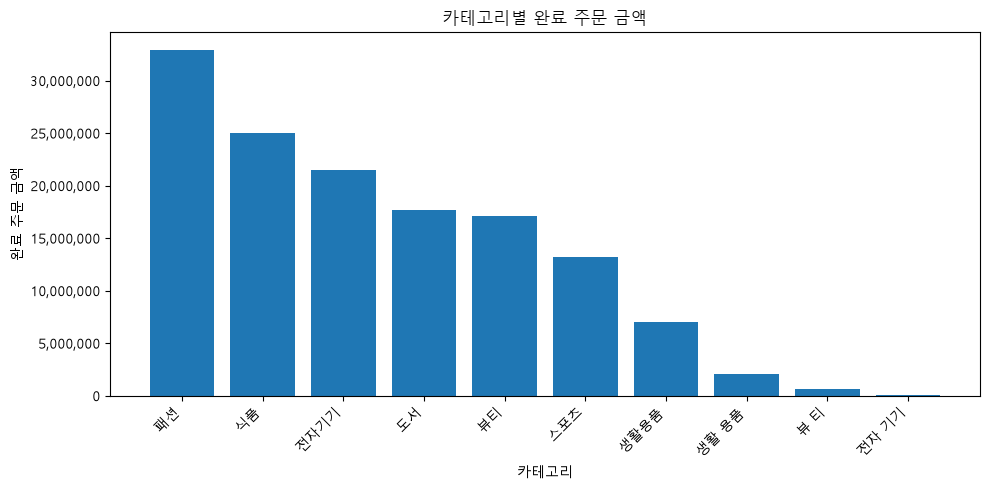

WindowsPath('c:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png')

In [13]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** completed 기준 카테고리별 금액은 패션 32,940,000원(23.99%), 식품 25,035,000원(18.23%), 전자기기 21,485,000원(15.65%) 순이었고, 막대 높이와 집계표 값이 일치했다(합계 137,325,000원). 그래프에는 카테고리가 7개가 아니라 10개로 그려졌고, 띄어쓰기만 다른 `생활 용품`, `뷰 티`, `전자 기기`가 별도의 작은 막대로 나타났다(합계 2,861,000원, 약 2.08%). 이 변형을 원래 카테고리에 합치면 뷰티(17,751,000원)가 도서(17,663,000원)보다 커져 4위와 5위가 뒤바뀐다.
- **해석:** 패션이 완료 주문 금액에서 가장 큰 비중을 차지한다. 다만 4위와 5위의 순서는 표기 변형을 어떻게 처리하느냐에 따라 달라지므로, 이 그래프만으로 뷰티가 도서보다 낮다고 말할 수 없다. 변형 막대는 실제로 매출이 작은 카테고리가 아니라 같은 카테고리가 쪼개져 보이는 것으로 판단했다.
- **한계:** 금액만으로 인기, 선호, 수익성을 알 수 없다. 상품 미연결 completed 16행(4,015,000원, 약 2.8%)은 이 그래프에 포함되지 않았다. 공백만 다른 표기가 같은 카테고리라는 것은 상품명으로 추정한 것이며 담당자 확인은 받지 못했다.
- **다음 질문:** 금액 차이가 판매 수량 때문인가, 단가 때문인가? 카테고리별 total_quantity와 평균 단가를 분리해서 비교하면 같은 순위가 나오는가? 상품 수가 많은 카테고리가 금액도 큰가?

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [14]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9479000.0,11,861727.0
1,2025-08,8892000.0,17,523059.0
2,2025-09,4519000.0,4,1129750.0
3,2025-10,12547000.0,17,738059.0
4,2025-11,9163000.0,16,572688.0
5,2025-12,8113000.0,12,676083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7107000.0,13,546692.0
9,2026-04,11459000.0,14,818500.0


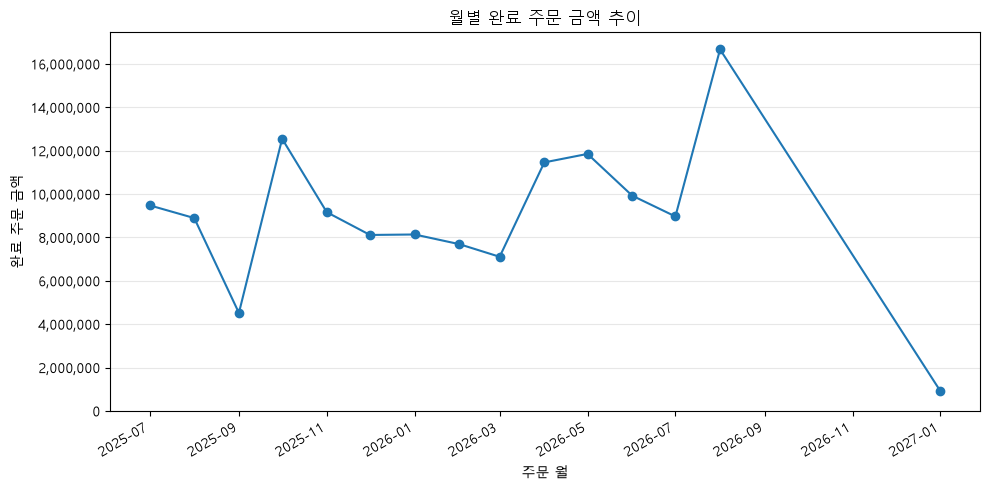

WindowsPath('c:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [15]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

### 그래프 2 기록

- **관찰:** 월별 completed 금액은 2025-09에 4,519,000원으로 가장 낮았다가 2025-10에 12,547,000원으로 크게 올랐고, 2026-03(7,107,000원)에서 2026-04(11,459,000원)/2026-05(11,850,000원)로 다시 올랐으며, 2026-08에 16,668,000원으로 최고점을 찍었다. 원래 그래프에서는 2026-08 이후 2027-01(909,000원, 1건)까지 직선이 이어져 마지막에 급락한 것처럼 보였다.
- **해석:** 주문 수와 평균 주문 금액이 항상 같이 움직이지는 않았다. 2025-10은 주문 수가 크게 늘면서 금액이 올랐고, 2026-08도 주문 수가 늘며 올랐다. 반면 2025-09는 주문이 4건뿐인데 평균 주문 금액이 높아 금액이 낮은 이유가 주문 수 부족임을 보여 준다. 즉 이번 데이터에서는 금액 변화가 주로 주문 수 변화와 함께 움직인 것으로 보인다(관찰 수준이며 인과는 아님). 마지막 급락처럼 보인 부분은 실제 감소가 아니라 데이터가 없는 2026-09~12 구간을 선으로 이은 결과이고, 2027-01은 현재 시점 이후의 이상 날짜 후보다.
- **한계:** 프로모션, 계절성, 신규 상품 출시 같은 원인은 현재 데이터에 없어 단정하지 않았다. 날짜 결측 completed 6행(1,903,000원)과 상품 미연결 16행(4,015,000원)은 그래프에 포함되지 않았다. 데이터 없는 월과 실제 거래 0건인 월은 구분할 수 없다.
- **다음 질문:** 월별 주문 수와 평균 주문 금액을 나란히 그려 어느 쪽이 금액 변화를 이끄는지 확인한다. 2027-01 주문의 order_id와 상태를 조회한다. 월별 카테고리 구성이 달라졌는지 본다.

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [18]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

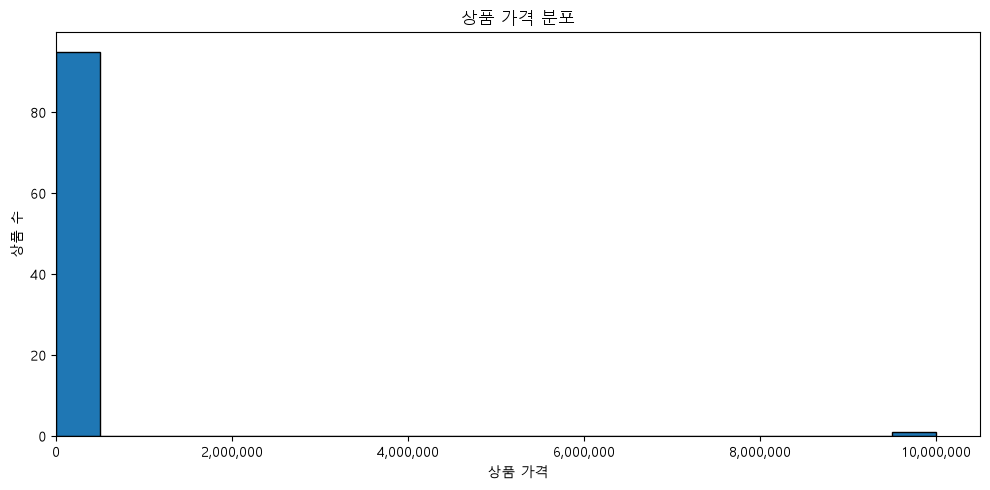

WindowsPath('c:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [19]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

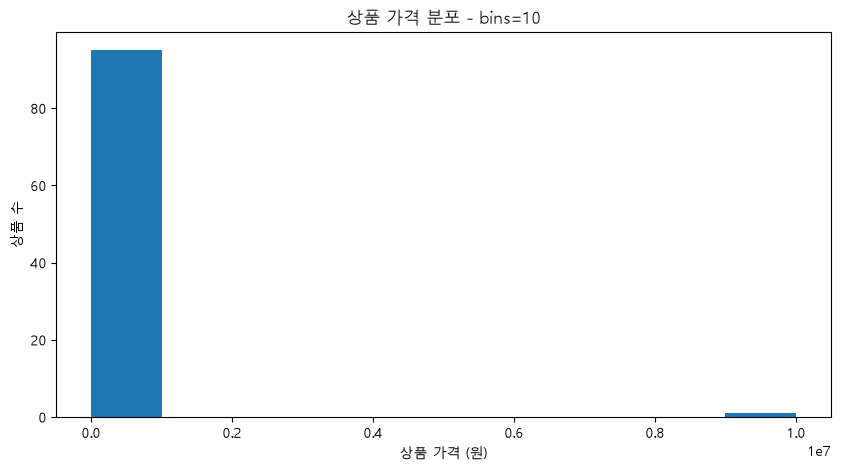

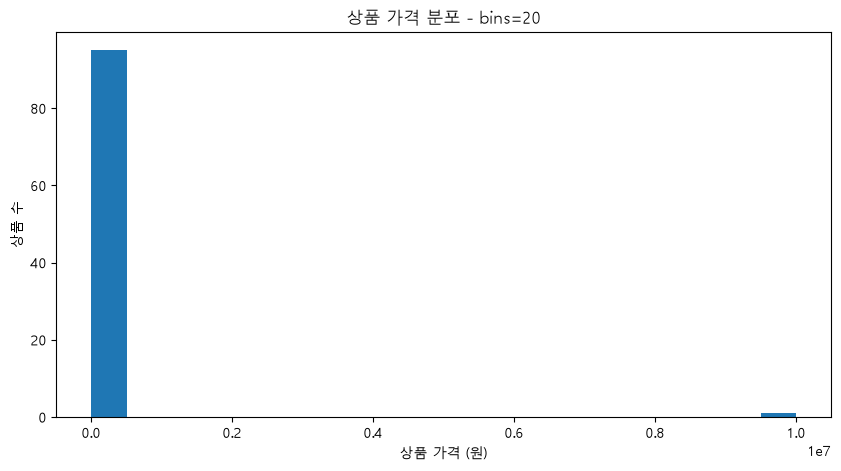

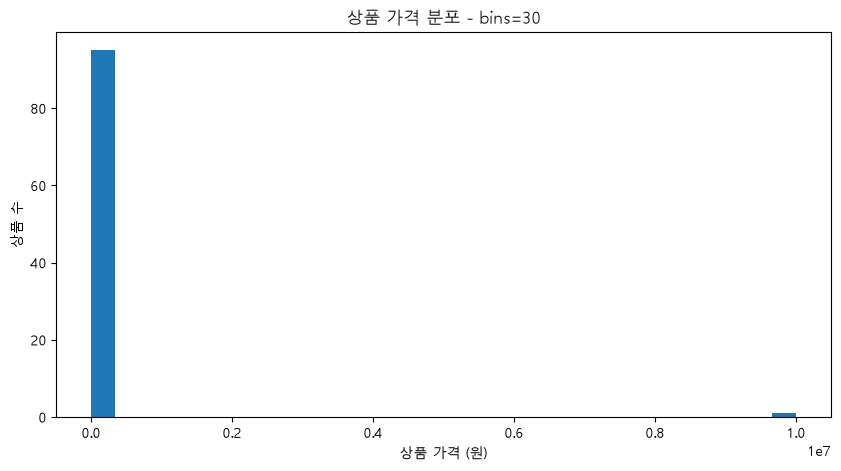

In [20]:
for bins in [10, 20, 30]:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(products["price"], bins=bins)
    ax.set_title(f"상품 가격 분포 - bins={bins}")
    ax.set_xlabel("상품 가격 (원)")
    ax.set_ylabel("상품 수")
    plt.show()

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?
  bins가 10, 20, 30으로 바뀌어도 거의 모든 상품(약 95개)이 가장 왼쪽의 막대 하나에 몰려 있고, 약 1,000만 원 부근에 상품 1개가 따로 떨어져 있는 패턴은 그대로 유지되었다. 이 패턴은 describe()의 최댓값 9,999,999원, 평균(204,896원)이 중앙값(94,500원)의 2배 이상인 결과와도 일치한다.

- 어떤 인상은 bins 선택에 따라 달라지는가?
  왼쪽 막대의 폭만 달라졌다(bins=10은 약 100만 원, bins=30은 약 33만 원 폭). 하지만 극단값 하나 때문에 x축이 1,000만 원까지 늘어나 있어서 어떤 bins에서도 나머지 95개 상품의 가격 분포(어느 구간에 많은지, 긴 꼬리가 있는지)는 보이지 않았다. bins를 늘려도 이 한계는 해결되지 않았다.

In [21]:
products[products["price"] == products["price"].max()]

,product_id,product_name,category,price
94,99,뷰티 상품 099,뷰티,9999999.0


## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [22]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
70,183000.0,37.0,6771000.0
90,96000.0,70.0,6720000.0
91,187000.0,26.0,4862000.0
61,193000.0,22.0,4246000.0
50,152000.0,26.0,3952000.0
66,168000.0,21.0,3528000.0
45,171000.0,19.0,3249000.0
36,172000.0,17.0,2924000.0
47,183000.0,15.0,2745000.0
81,145000.0,18.0,2610000.0


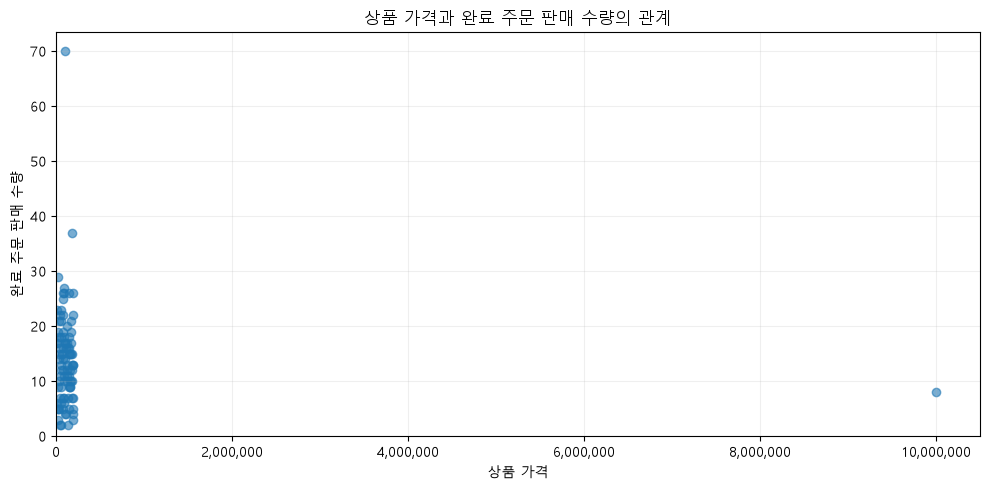

WindowsPath('c:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [23]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 대부분의 상품이 가격 0~20만 원, completed 판매 수량 0~30개 범위에 몰려 있다. 9,999,999원 상품 1개는 오른쪽 끝에 따로 있고 판매 수량은 약 8개다. 판매 수량이 70개(가격 96,000원)와 37개(가격 183,000원)인 상품 두 개가 다른 점들보다 위로 튄다. 상위 10개 표의 수량과 점 위치가 일치했다.
- **해석:** 가격이 올라갈수록 수량이 일정하게 늘거나 줄어드는 뚜렷한 관계는 보이지 않는다. 극단값 하나가 x축을 1,000만 원까지 늘려서 나머지 점들의 모양이 왼쪽에 압축되어 보이므로 이 그래프만으로는 관계의 유무를 판단하기 어렵다. 수량이 큰 두 상품은 대량 주문 한두 건의 영향일 수 있으나 확인하지 않았다.
- **한계:** 카테고리, 할인 및 프로모션, 상품 노출, 재고, 판매 기간은 현재 데이터에 없다. 그래서 가격이 판매 수량에 영향을 주었다거나 주지 않았다고 말할 수 없다. 관계가 보이거나 보이지 않는 것은 원인을 증명하지 않는다. 상품 미연결 completed 16행(4,015,000원)은 포함되지 않았다.
- **다음 질문:** 극단값(product_id 99)을 제외하고 다시 그리면 가격과 수량의 관계가 보이는가? 카테고리별로 색을 나누면 패턴이 달라지는가? 수량 70개 상품은 주문 몇 건에서 나온 것인가? 판매 기간(첫/마지막 주문일)을 상품별로 비교하면 어떤가?

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [24]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
1,3,3,6702000.0,2234000.0
7,14,4,5122000.0,1280500.0
57,90,3,4311000.0,1437000.0
47,65,6,3977000.0,662833.0
66,104,2,3966000.0,1983000.0
59,93,4,3845000.0,961250.0
11,20,4,3808000.0,952000.0
27,38,4,3656000.0,914000.0
19,28,4,3201000.0,800250.0
55,85,4,2832000.0,708000.0


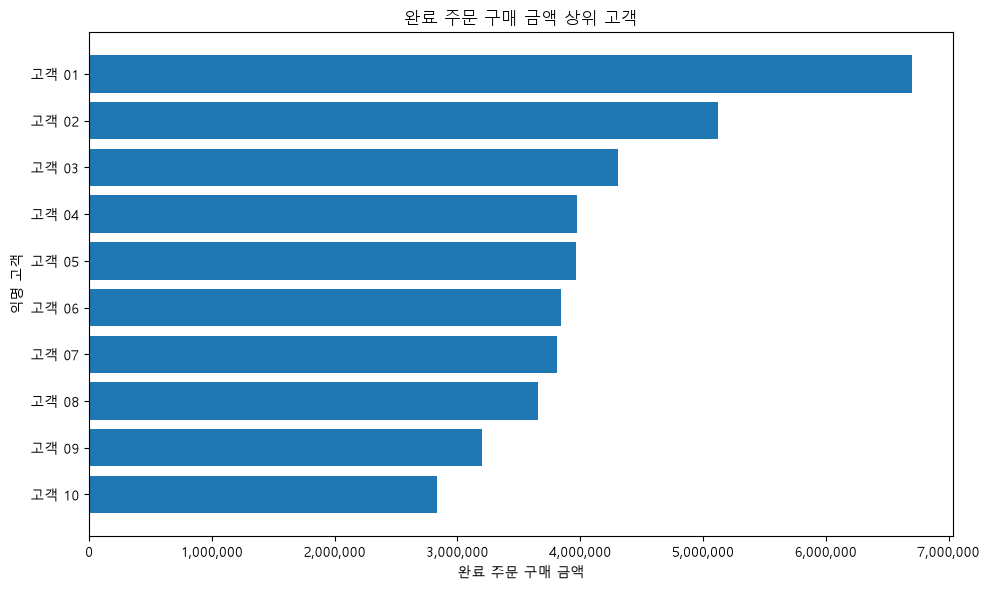

WindowsPath('c:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png')

In [25]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

### 시각화 질문 (추가 그래프: 상위 고객 가로 막대)

- 질문: completed 기준 구매 금액이 높은 고객은 누구이며, 반복 구매인가 단발 고액 구매인가?
- 분석 범위: completed, 상품 연결 건, 상위 10명 (익명 라벨 사용)
- 선택한 그래프: 가로 막대그래프
- 선택 이유: 순위가 있는 범주(고객)의 금액 비교, 라벨이 길어도 읽기 쉬움

### 원본 집계값

상위 1위 6,702,000원(3건, 평균 2,234,000원), 2위 5,122,000원(4건), 3위 4,311,000원(3건), 10위 2,832,000원(4건)

### 결과 관찰

1위 고객은 주문 3건에 건당 평균 2,234,000원으로 금액이 크다. 4위 고객은 6건이지만 평균 662,833원이다. 그래프에는 실명 대신 익명 라벨만 표시되었다. 이 집계는 completed 기준이라 취소·환불 거래는 포함되지 않는다.

### 나의 해석과 판단

금액이 높다는 사실만으로 충성 고객이라 부를 수 없다. 1위는 건당 금액이 큰 편이고 4위는 반복 구매가 많아 서로 다른 유형으로 보인다. 분석 기간이 약 14개월이고 건수가 3~6건이라 패턴을 일반화하기에는 표본이 작다.

### 업무·분석적 의미

우수 고객 선정 시 총금액만이 아니라 주문 횟수와 평균 주문 금액을 함께 봐야 한다. Chapter06에서 completed 필터링 없이 집계하면 취소/환불 고객(고객 18번)이 1위로 잘못 나왔던 점도 기준 선택의 중요성을 보여 준다.

### 한계와 추가 확인 사항

상품 미연결 completed 16행과 날짜 결측 6행의 금액은 일부 고객 금액에서 빠져 있을 수 있다. 재구매 의도나 만족도는 현재 데이터로 알 수 없다. 반복 구매 간격과 구매 카테고리를 추가로 확인한다.

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [26]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


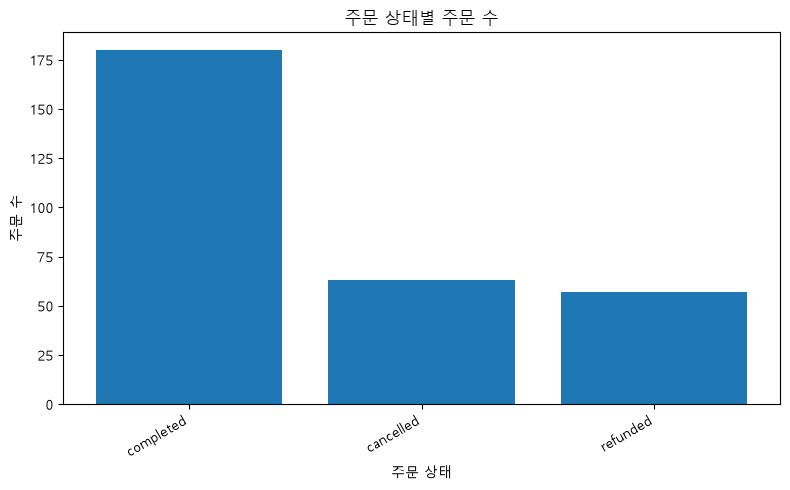

WindowsPath('c:/dev/llm-data-analysis-study/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png')

In [27]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

### 시각화 질문 (추가 그래프: 주문 상태별 주문 수)

- 질문: 주문 상태별 주문 수는 어떻게 다른가?
- 분석 범위: 전체 주문 300건 (상태 필터 없음)
- 선택한 그래프: 막대그래프
- 선택 이유: 3개 범주의 크기 비교가 목적

### 원본 집계값

completed 180건(60.0%), cancelled 63건(21.0%), refunded 57건(19.0%), 합계 300건

### 결과 관찰

completed가 가장 많고, cancelled와 refunded는 각각 60건 안팎으로 비슷하다. 전체의 40%가 완료되지 않은 주문이다. 막대 높이는 집계표 값과 일치하고 y축은 0에서 시작한다.

### 나의 해석과 판단

금액 분석을 completed로 제한하는 것이 필요한 이유를 보여 준다. 취소/환불이 전체 주문의 40%라서, 이를 포함하면 금액이 크게 과대 집계된다(Chapter04에서 전체 합계가 completed 합계보다 약 1.7배 컸던 것과 같은 맥락이다).

### 업무·분석적 의미

완료율(60%)은 운영 지표로 쓸 수 있으나, 이 그래프만으로 취소/환불이 왜 일어났는지는 알 수 없다.

### 한계와 추가 확인 사항

취소/환불의 원인(결제수단, 카테고리, 시기)은 현재 그래프로 설명할 수 없다. 결제수단별/카테고리별 취소/환불 비율을 추가로 확인한다.

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

### 그래프 정확성 검증

| 그래프 | 원본 집계값 | 그래프 값 일치 | 범위 일치 | 발견한 문제 | 수정 내용 |
| --- | --- | --- | --- | --- | --- |
| 카테고리별 completed 금액 (막대) | 합계 137,325,000원 (검증표 passed) | PASS (패션 약 3,294만, 식품 약 2,500만 등) | PASS (completed, 상품 연결 건) | 표기 변형 3개(생활 용품, 뷰 티, 전자 기기)가 별도 막대로 쪼개짐, 합산하면 뷰티가 도서보다 위 | 원본 그래프 유지, 해석과 한계에 기록 |
| 월별 completed 금액 (선) | 합계 135,422,000원 (검증표 passed) | PASS (2025-09 약 450만, 2026-08 약 1,667만) | PASS (completed, 유효 날짜) | 2026-08에서 2027-01로 직선이 이어져 급락처럼 보임, 2026-09~12는 데이터 없음 | 원본 그래프 유지, 해석에서 보정 |
| 상품 가격 분포 (히스토그램) | 상품 96개, 최댓값 9,999,999원 | PASS (bins 10/20/30 모두 95개 + 1개) | PASS (전체 상품 마스터) | 극단값 1개 때문에 나머지 분포가 보이지 않음 | 삭제하지 않고 후보로 기록 |
| 가격 vs 판매 수량 (산점도) | 상위 수량 70개, 37개 등 | PASS (상위 10개 표와 점 위치 일치) | PASS (completed) | 극단값이 x축을 늘려 왼쪽이 압축됨 | 해석에서 보정 |
| 상위 고객 (가로 막대) | 1위 6,702,000원 | PASS | PASS (completed, 합계는 상품 연결 건) | 없음 (익명 라벨 사용) | 해당 없음 |
| 주문 상태 (막대) | 180 / 63 / 57, 합계 300 | PASS | PASS (전체 주문) | 없음 | 해당 없음 |

### 오해 점검 체크

- [x] 막대그래프 값 축이 0에서 시작한다.
- [x] 금액 축에 단위(원)와 천 단위 쉼표가 있다.
- [x] 월 축이 시간순이다.
- [ ] 월별 그래프에서 데이터 없는 구간(2026-09~12)이 구분되지 않는다. (원본 그래프는 선으로 이어 그림)
- [x] 제목에 분석 범위가 있다. (완료 주문 등)
- [x] 상위 고객 그래프에 실명이 없다.
- [ ] 카테고리 그래프의 표기 변형이 합쳐지지 않았다.

### 내가 발견한 시각화 위험 또는 개선점

- 문제: (1) 월별 선그래프가 데이터 없는 2026-09~12를 건너뛰고 2027-01까지 직선으로 이어 급락처럼 보임. (2) 카테고리 막대그래프에서 같은 카테고리가 띄어쓰기 차이로 쪼개져 4, 5위 순서가 달라 보임.
- 왜 오해를 만들 수 있는가: (1)은 '없는 달'을 점진적 감소로 읽게 하고, 2027-01은 현재 시점 이후의 이상 날짜 후보다. (2)는 뷰티가 도서보다 낮다고 잘못 읽게 한다.
- 수정 방법: 원본 그래프는 유지하고, 해석과 한계 칸에 보정 내용을 적었다. 필요하면 2027-01을 선에서 분리하거나 카테고리를 합산해 다시 그릴 수 있다.
- 수정 후 확인 결과: 합산(cat_merged) 표로 합계 137,325,000원이 유지됨을 확인했고 뷰티 17,751,000원 > 도서 17,663,000원으로 순위가 바뀜을 기록함.

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [28]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures\ch07_category_completed_amount_bar.png
- c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures\ch07_monthly_completed_amount_line.png
- c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures\ch07_product_price_hist.png
- c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures\ch07_price_completed_quantity_scatter.png
- c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures\ch07_top_customers_anonymized_barh.png
- c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\figures\ch07_order_status_bar.png
요약 보고서: c:\dev\llm-data-analysis-study\llm-data-analysis-course\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


### 스크립트 재실행 결과 (scripts/run_visualization.py)

- 실행: python -m scripts.run_visualization
- 결과: ValueError "주문 정보와 연결되지 않은 주문 상세가 있습니다: 2행" 발생, 그래프 저장 전 중단
- 원인: 스크립트는 data/processed를 그대로 입력으로 사용하는데, 이 폴더의 order_items에는 orders에 없는 order_id 9991, 9992가 있음(Chapter05에서 발견). 노트북은 처음에 같은 에러가 나서 해당 2행을 제외한 사본(data/processed_viz)으로 진행했음
- 비교: 노트북과 스크립트는 입력 데이터가 달랐기 때문에 숫자를 직접 비교할 수 없다. 어느 쪽이 맞다고 결정하지 않고, 입력 데이터와 필터 조건을 먼저 비교해야 한다고 판단함
- 확인: 같은 사본(data/processed_viz)을 쓰면 검증표 4개가 passed = True이며 합계가 노트북과 일치하는지 확인함 (B를 실행한 경우 결과 기재)
- 한계: 스크립트가 데이터 품질 문제를 만나면 조용히 넘어가지 않고 멈추도록 설계되어 있어 문제 발견에는 도움이 되지만, 이번 데이터에서는 Chapter05 처리 기준(고아 레코드 제거 여부)을 먼저 정해야 끝까지 실행된다.

## 11. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

카테고리별 completed 금액 막대그래프를 가장 중요하게 봤다. 집계 검증표(passed = True)와 합계가 일치한다는 것을 확인한 뒤 그렸고, 검증 과정에서 카테고리 표기 변형 때문에 순위가 달라 보이는 문제를 발견했기 때문이다.

### 그래프에서 직접 확인한 사실

- 패션이 32,940,000원(23.99%)으로 가장 크고, 식품 25,035,000원(18.23%), 전자기기 21,485,000원(15.65%) 순이다.
- 그래프에는 카테고리가 7개가 아니라 10개로 그려졌다. 띄어쓰기만 다른 생활 용품, 뷰 티, 전자 기기가 별도 막대로 나타났고 합계는 2,861,000원이다.
- 이 변형을 합산하면 뷰티(17,751,000원)가 도서(17,663,000원)보다 커져 4위와 5위가 바뀐다.

### 내가 해석한 내용

패션이 완료 주문 금액에서 가장 큰 비중을 차지한다. 다만 4위와 5위 순서는 표기 변형을 어떻게 처리하느냐에 따라 달라지므로, 이 그래프만으로 뷰티가 도서보다 낮다고 말할 수 없다. 월별 선그래프의 마지막 급락은 실제 감소가 아니라 데이터가 없는 2026-09~12를 직선으로 이은 결과로 보았다. 상품 가격 분포에서는 평균(204,896원)이 중앙값(94,500원)의 2배 이상인데, 이는 9,999,999원 상품 1개 때문으로 보았다.

### 그래프만으로 말할 수 없는 것

- 금액이 크다는 사실만으로 인기, 선호, 수익성을 말할 수 없다.
- 월별 증감의 원인(프로모션, 계절성 등)은 현재 데이터에 없다.
- 가격과 판매 수량의 관계가 보이거나 보이지 않는다는 것이 원인을 증명하지 않는다.
- 취소/환불이 왜 발생했는지는 주문 상태 그래프로 알 수 없다.
- 9,999,999원 상품, 2027-01 주문, 수량 70개 상품이 입력 오류인지 실제 값인지는 알 수 없다.

### 오해를 줄이기 위해 수정하거나 확인한 요소

- 축: 막대그래프 값 축이 0에서 시작하는지 확인했다. 월별 그래프에서 2026-08과 2027-01이 직선으로 이어지는 문제를 발견해 기록했다.
- 단위: 금액 축에 단위와 천 단위 쉼표가 있는지 확인했다.
- 정렬: 막대는 금액 내림차순, 월별은 시간순인지 집계표와 대조했다.
- 범위: 금액 그래프는 completed로 고정했고, 제외한 행(주문 미연결 2행 922,000원, 상품 미연결 16행 4,015,000원, 날짜 결측 6행 1,903,000원)을 기록했다. 원본 processed는 수정하지 않았다.
- 개인정보: 상위 고객 그래프는 실명 대신 익명 라벨을 사용했고 표에 name 컬럼이 없음을 확인했다.

### 다음 분석에서 확인하고 싶은 질문

- 금액 차이는 판매 수량 때문인가, 단가 때문인가?
- 월별 주문 수와 평균 주문 금액 중 무엇이 금액 변화를 이끄는가?
- 극단값(product_id 99)과 2027-01 주문을 제외하면 가격 분포와 월별 추세는 어떻게 달라지는가?
- 취소/환불 비율은 결제수단이나 카테고리에 따라 다른가?

---

## 완료 체크

- [x] 질문을 그래프보다 먼저 정했습니다.
- [x] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [x] 집계 검증표의 `passed`를 확인했습니다.
- [x] 대표 그래프 3개 이상을 만들었습니다.
- [x] 그래프와 원본 집계값을 교차 확인했습니다.
- [x] 축·단위·정렬·범위를 확인했습니다.
- [x] 관계를 원인으로 단정하지 않았습니다.
- [x] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [x] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [x] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다. (노트북에서 그래프 6개와 요약 보고서 생성을 확인했고, scripts/run_visualization.py는 입력 데이터 문제로 ValueError가 나서 에러만 기록했습니다.)

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.